# Etapa 3: protocolo de avaliação e pontos de referência

Entrada: `data/processed/emprestimos.csv`, gerado pela etapa 1.

Antes da rede neural, esta etapa fixa a régua: o protocolo de avaliação que todos os modelos seguem e o desempenho de modelos simples, contra os quais a rede será comparada.

**Protocolo** (código em `src/avaliacao.py`):

- **Divisão estratificada 80/20**: 3.415 pedidos de treino e 854 de teste, com 62,2% de aprovados nos dois lados.
- **10 seeds** (0 a 9): cada seed sorteia outra divisão; as tabelas trazem média ± desvio.
- **Validação cruzada estratificada de 5 partes dentro do treino** para escolher hiperparâmetros. O teste só é usado uma vez, no fim.
- **Métricas**: acurácia, F1 macro (média do F1 das duas classes) e AUC. A AUC mede se o modelo ordena bem os pedidos: é a chance de um aprovado sorteado receber probabilidade maior que um rejeitado sorteado (0,5 = sorteio; 1 = ordem perfeita).
- **Tempo**: um núcleo só para todos os modelos, uma rodada de aquecimento descartada, tempo de treino do modelo final separado do tempo da busca em grade, e mediana das 10 seeds.

Máquina: AMD Ryzen 5 9600X (6 núcleos, 12 threads), 31 GB de RAM, Windows 11, Python 3.14 e scikit-learn 1.9.1.

## 0. Configuração

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

from src import avaliacao, config

X, y = avaliacao.carregar()
print(X.shape, "| aprovados:", round(y.mean(), 3))

(4269, 11) | aprovados: 0.622


## 1. A divisão estratificada

In [2]:
X_tr, X_te, y_tr, y_te = avaliacao.dividir(X, y, seed=0)
pd.DataFrame({
    "pedidos": [len(y), len(y_tr), len(y_te)],
    "% aprovados": [round(100 * s.mean(), 1) for s in (y, y_tr, y_te)],
}, index=["base inteira", "treino", "teste"])

,pedidos,% aprovados
base inteira,4269,62.2
treino,3415,62.2
teste,854,62.2


## 2. Os pontos de referência

- **Classe majoritária**: responde sempre "aprovado". É o piso.
- **Regra de um corte**: uma árvore de profundidade 1, que aprende só com o treino um limiar para um único atributo. É a versão honesta da regra "score ≥ 550", cujo limiar foi escolhido olhando a base inteira.
- **Regressão logística**: um único neurônio com sigmoide, com os atributos padronizados. É a rede neural mais simples possível.
- **Árvore de decisão**: com busca em grade (critério, profundidade máxima e mínimo de pedidos por folha, 30 combinações), como na atividade 1.
- **Random Forest**: 300 árvores, configuração padrão, como na atividade 2.

A padronização da regressão logística fica dentro de um `Pipeline`, para ser calculada só com o treino.

In [3]:
GRADE_ARVORE = {
    "criterion": ["gini", "entropy"],
    "max_depth": [3, 5, 8, 12, None],
    "min_samples_leaf": [1, 5, 20],
}

def referencias(seed):
    return {
        "classe majoritária": DummyClassifier(strategy="most_frequent"),
        "regra de um corte": DecisionTreeClassifier(max_depth=1, random_state=seed),
        "regressão logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
        "árvore de decisão": GridSearchCV(DecisionTreeClassifier(random_state=seed), GRADE_ARVORE,
                                          cv=avaliacao.validacao_cruzada(seed), n_jobs=1),
        "random forest": RandomForestClassifier(n_estimators=300, random_state=seed, n_jobs=1),
    }

## 3. Resultados nas 10 seeds

In [4]:
resultados = avaliacao.rodar_seeds(referencias, X, y)

config.RESULTS_DIR.mkdir(exist_ok=True)
resultados.to_csv(config.RESULTS_DIR / "referencias.csv", index=False)

avaliacao.resumir(resultados)

,acurácia,F1 macro,AUC,erros (média),tempo de treino (s) · mediana,tempo da busca (s) · mediana,tempo de previsão (ms) · mediana
modelo,,,,,,,
classe majoritária,62.2 ± 0.0,38.3 ± 0.0,50.0 ± 0.0,323.0,0.0002,NaN,0.0315
regra de um corte,95.5 ± 0.6,95.3 ± 0.6,96.2 ± 0.5,38.8,0.0019,NaN,0.3336
regressão logística,91.9 ± 1.1,91.3 ± 1.2,97.0 ± 0.5,69.5,0.0035,NaN,0.5340
árvore de decisão,98.1 ± 0.4,98.0 ± 0.5,98.7 ± 0.6,16.0,0.0037,0.6516,0.3286
random forest,98.3 ± 0.4,98.2 ± 0.5,99.8 ± 0.1,14.5,0.4898,NaN,15.2717


## 4. O limiar aprendido pela regra de um corte

In [5]:
limiares = []
for seed in config.SEEDS:
    X_tr, X_te, y_tr, y_te = avaliacao.dividir(X, y, seed)
    arvore = DecisionTreeClassifier(max_depth=1, random_state=seed).fit(X_tr, y_tr)
    limiares.append({"seed": seed, "atributo": config.NOMES[config.FEATURES[arvore.tree_.feature[0]]],
                     "limiar": arvore.tree_.threshold[0]})
pd.DataFrame(limiares).set_index("seed").T

seed,0,1,2,3,4,5,6,7,8,9
atributo,score de crédito,score de crédito,score de crédito,score de crédito,score de crédito,score de crédito,score de crédito,score de crédito,score de crédito,score de crédito
limiar,549.5,549.5,549.5,549.5,549.5,549.5,549.5,549.5,549.5,549.5


## 5. Comparações seed a seed

In [6]:
pares = resultados.pivot(index="seed", columns="modelo", values="acurácia")
comparacoes = {
    "árvore − regra de um corte": pares["árvore de decisão"] - pares["regra de um corte"],
    "random forest − árvore": pares["random forest"] - pares["árvore de decisão"],
    "regressão logística − regra de um corte": pares["regressão logística"] - pares["regra de um corte"],
}
pd.DataFrame({
    nome: {"diferença média (pontos)": round(100 * d.mean(), 2), "desvio (pontos)": round(100 * d.std(), 2),
           "seeds com diferença positiva": int((d > 0).sum())}
    for nome, d in comparacoes.items()
}).T

,diferença média (pontos),desvio (pontos),seeds com diferença positiva
árvore − regra de um corte,2.67,0.71,10.0
random forest − árvore,0.18,0.70,5.0
regressão logística − regra de um corte,-3.59,0.87,0.0


## 6. Acurácia e tempo de treino

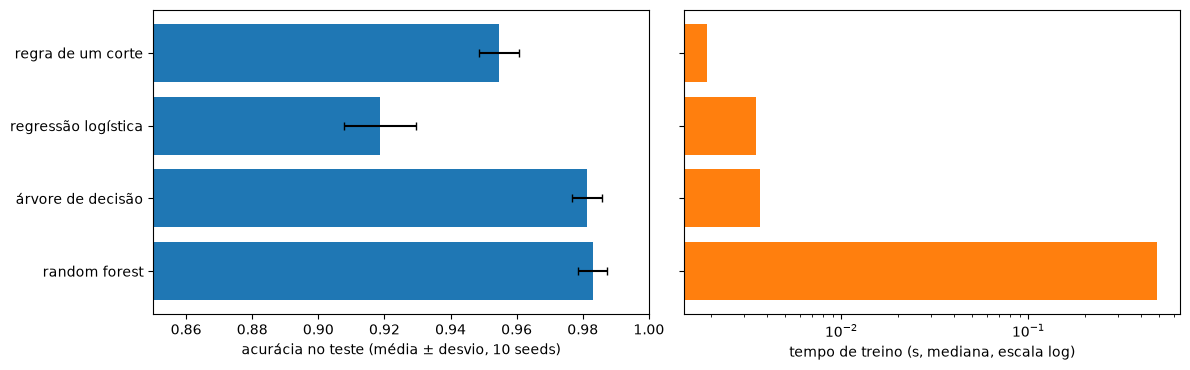

In [7]:
modelos = [m for m in resultados["modelo"].unique() if m != "classe majoritária"]
grupos = resultados.groupby("modelo")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8))
media, desvio = grupos["acurácia"].mean()[modelos], grupos["acurácia"].std()[modelos]
ax1.barh(modelos, media, xerr=desvio, color="tab:blue", capsize=3)
ax1.set_xlim(0.85, 1.0)
ax1.set_xlabel("acurácia no teste (média ± desvio, 10 seeds)")
ax1.invert_yaxis()

tempo = grupos["tempo de treino (s)"].median()[modelos]
ax2.barh(modelos, tempo, color="tab:orange")
ax2.set_xscale("log")
ax2.set_xlabel("tempo de treino (s, mediana, escala log)")
ax2.invert_yaxis()
ax2.set_yticklabels([])
plt.tight_layout()
plt.show()

**Resultado.** A régua para a rede neural, em média de 10 seeds:

- **Piso**: responder sempre "aprovado" acerta 62,2%.
- **Regra de um corte**: 95,5 ± 0,6%. Aprendendo só com o treino, a árvore de profundidade 1 escolhe o score de crédito com limiar 549,5 nas 10 seeds, a mesma regra encontrada na análise exploratória.
- **Regressão logística** (um único neurônio): 91,9 ± 1,1%, abaixo da regra de um corte nas 10 seeds (−3,6 pontos). Ela só soma os atributos com pesos, sem combinar "se o score for baixo, olhe o prazo", e sua transição de rejeitado para aprovado é suave, enquanto a regra é um degrau. Ainda assim, sua AUC (97,0) é maior que a da regra (96,2): ela ordena bem os pedidos, mas o corte em probabilidade 0,5 erra os que ficam perto do degrau.
- **Árvore de decisão ajustada**: 98,1 ± 0,4%, cerca de 16 erros em 854. Supera a regra de um corte nas 10 seeds (+2,7 pontos): as perguntas seguintes capturam a exceção dos prazos curtos.
- **Random Forest**: 98,3 ± 0,4%, com a maior AUC (99,8). Contra a árvore, a diferença é de 0,2 ponto, positiva em só 5 das 10 seeds: empate.

**Tempo** (um núcleo, mediana de 10 seeds): a árvore e a regressão logística treinam em poucos milissegundos; a Random Forest de 300 árvores leva cerca de meio segundo, mais de 100 vezes a árvore, e também é a mais lenta para prever. A busca em grade da árvore (30 combinações × 5 partes) leva menos de um segundo. Os valores absolutos variam um pouco de uma execução para outra; as proporções entre os modelos são estáveis.

Para a rede neural, isso significa: superar 95,5% (a regra de um corte) e se aproximar de 98% (a árvore e a floresta). A regressão logística mostra que um único neurônio não basta.